In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal

print("Installations Working!")

Installations Working!


## Instructor Provide Code

In [2]:
import numpy as np

def hw2q2():
    Ntrain = 100
    data = generateData(Ntrain)
    plot3(data[0,:],data[1,:],data[2,:])
    xTrain = data[0:2,:]
    yTrain = data[2,:]
    
    Ntrain = 1000
    data = generateData(Ntrain)
    plot3(data[0,:],data[1,:],data[2,:])
    xValidate = data[0:2,:]
    yValidate = data[2,:]
    
    return xTrain,yTrain,xValidate,yValidate

def generateData(N):
    gmmParameters = {}
    gmmParameters['priors'] = [.3,.4,.3] # priors should be a row vector
    gmmParameters['meanVectors'] = np.array([[-10, 0, 10], [0, 0, 0], [10, 0, -10]])
    gmmParameters['covMatrices'] = np.zeros((3, 3, 3))
    gmmParameters['covMatrices'][:,:,0] = np.array([[1, 0, -3], [0, 1, 0], [-3, 0, 15]])
    gmmParameters['covMatrices'][:,:,1] = np.array([[8, 0, 0], [0, .5, 0], [0, 0, .5]])
    gmmParameters['covMatrices'][:,:,2] = np.array([[1, 0, -3], [0, 1, 0], [-3, 0, 15]])
    x,labels = generateDataFromGMM(N,gmmParameters)
    return x

def generateDataFromGMM(N,gmmParameters):
#    Generates N vector samples from the specified mixture of Gaussians
#    Returns samples and their component labels
#    Data dimensionality is determined by the size of mu/Sigma parameters
    priors = gmmParameters['priors'] # priors should be a row vector
    meanVectors = gmmParameters['meanVectors']
    covMatrices = gmmParameters['covMatrices']
    n = meanVectors.shape[0] # Data dimensionality
    C = len(priors) # Number of components
    x = np.zeros((n,N))
    labels = np.zeros((1,N))
    # Decide randomly which samples will come from each component
    u = np.random.random((1,N))
    thresholds = np.zeros((1,C+1))
    thresholds[:,0:C] = np.cumsum(priors)
    thresholds[:,C] = 1
    for l in range(C):
        indl = np.where(u <= float(thresholds[:,l]))
        Nl = len(indl[1])
        labels[indl] = (l+1)*1
        u[indl] = 1.1
        x[:,indl[1]] = np.transpose(np.random.multivariate_normal(meanVectors[:,l], covMatrices[:,:,l], Nl))
        
    return x,labels

def plot3(a,b,c,mark="o",col="b"):
  from matplotlib import pyplot
  import pylab
  from mpl_toolkits.mplot3d import Axes3D
  pylab.ion()
  fig = pylab.figure()
  ax = Axes3D(fig)
  ax.scatter(a, b, c,marker=mark,color=col)
  ax.set_xlabel("x1")
  ax.set_ylabel("x2")
  ax.set_zlabel("y")
  ax.set_title('Training Dataset')

In [3]:
hw2q2()

TypeError: only 0-dimensional arrays can be converted to Python scalars

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def hw2q2(seed=None):
    if seed is not None:                       # FIX: optional reproducibility
        np.random.seed(seed)

    Ntrain = 100
    data = generateData(Ntrain)
    plot3(data[0,:], data[1,:], data[2,:], title='Training Dataset')
    xTrain = data[0:2,:]
    yTrain = data[2,:]

    Nvalidate = 1000
    data = generateData(Nvalidate)
    plot3(data[0,:], data[1,:], data[2,:], title='Validation Dataset')   # FIX: title
    xValidate = data[0:2,:]
    yValidate = data[2,:]

    return xTrain, yTrain, xValidate, yValidate

def generateData(N):
    gmmParameters = {}
    gmmParameters['priors'] = [.3, .4, .3]
    gmmParameters['meanVectors'] = np.array([[-10, 0, 10], [0, 0, 0], [10, 0, -10]])
    gmmParameters['covMatrices'] = np.zeros((3, 3, 3))
    gmmParameters['covMatrices'][:,:,0] = np.array([[1, 0, -3], [0, 1, 0], [-3, 0, 15]])
    gmmParameters['covMatrices'][:,:,1] = np.array([[8, 0, 0], [0, .5, 0], [0, 0, .5]])
    gmmParameters['covMatrices'][:,:,2] = np.array([[1, 0, -3], [0, 1, 0], [-3, 0, 15]])
    x, labels = generateDataFromGMM(N, gmmParameters)
    return x

def generateDataFromGMM(N, gmmParameters):
    priors = gmmParameters['priors']
    meanVectors = gmmParameters['meanVectors']
    covMatrices = gmmParameters['covMatrices']
    n = meanVectors.shape[0]
    C = len(priors)
    x = np.zeros((n, N))
    labels = np.zeros((1, N))
    u = np.random.random((1, N))
    thresholds = np.zeros((1, C+1))
    thresholds[:, 0:C] = np.cumsum(priors)
    thresholds[:, C] = 1
    for l in range(C):
        indl = np.where(u <= thresholds[0, l])          # FIX: was float(thresholds[:,l])
        Nl = len(indl[1])
        labels[indl] = (l+1)*1
        u[indl] = 1.1
        x[:, indl[1]] = np.transpose(np.random.multivariate_normal(meanVectors[:,l], covMatrices[:,:,l], Nl))
    return x, labels

def plot3(a, b, c, mark="o", col="b", title="Dataset"):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')               # FIX: was Axes3D(fig)
    ax.scatter(a, b, c, marker=mark, color=col)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")
    ax.set_title(title)
    plt.show()

In [ ]:

def z_cubic(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([np.ones(len(X)), x1, x2, x1**2, x1*x2, x2**2, x1**3, x1**2*x2, x1*x2**2, x2**3])

def nll(w, Z, l):
    a = Z @ w
    return np.mean(l * np.logaddexp(0, -a) + (1 - l) * np.logaddexp(0, a))



def ml_opt(w, Z_train, y_Train):
    res = scipy.optimize.minimize(ml_objective, w, args=(Z_train, y_Train))
    print(res.success, res.message)
    return res.x

def map_opt(w, Z_train, y_Train, gamma, sigma2):
    res = scipy.optimize.minimize(map_objective, w, args=(Z_train, y_Train, gamma, sigma2))
    print(res.success, res.message)
    return res.x


def ml_objective(w, Z, y):
    r = y - Z @ w
    return np.mean(r**2) 

def map_objective(w, Z, y, gamma, sigma2):
    r = y - Z @ w 
    return np.mean(r**2) + (sigma2 / (len(y) * gamma)) * np.sum(w**2)

def avg_sq_error(Z_val, y_val, w):
    return np.mean(ml_objective(w, Z_val, y_val))


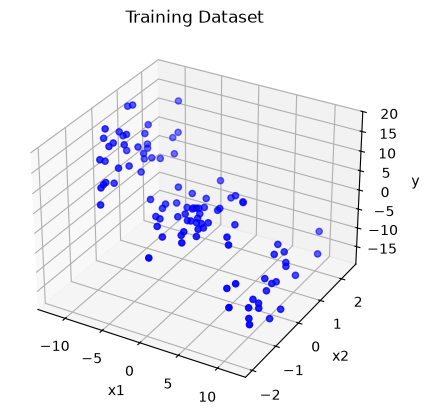

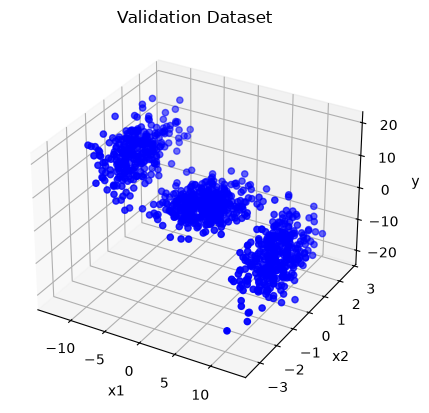

(100, 10)
(1000, 10)
True Optimization terminated successfully.
ML Parameter Estimation:
train: 2.8466042119488693
val:   4.06598520586414
True Optimization terminated successfully.
MAP Parameter Estimation:


TypeError: map_objective() missing 2 required positional arguments: 'gamma' and 'sigma2'

In [24]:
xTrain, yTrain, xValidate, yValidate = hw2q2(0)

X_train = xTrain.T        # (100, 2)
X_val   = xValidate.T     # (1000, 2)

Z_train = z_cubic(X_train)
Z_val   = z_cubic(X_val)

print(Z_train.shape)   # should be (100, 10)
print(Z_val.shape)     # should be (1000, 10)

w0 = np.zeros(Z_train.shape[1])# ML Estimation

w_ML = ml_opt(w0, Z_train, yTrain)   
err_ML = avg_sq_error(Z_val, yValidate, w_ML)

print("ML Parameter Estimation:")

print("train:", ml_objective(w_ML, Z_train, yTrain))
print("val:  ", err_ML)


map_w0 = np.zeros(Z_train.shape[1])# MAP Estimation

w_Map = ml_opt(map_w0, Z_train, yTrain)   
err_Map = avg_sq_error(Z_val, yValidate, w_Map)

print("MAP Parameter Estimation:")

print("train:", map_objective(w_Map, Z_train, yTrain))
print("val:  ", err_Map)
